In [13]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
from scipy.special import erf
from scipy import constants 

Mearth = 5.972e27
Msun = 1.989e33
AU = 1.4959787069e13
yr = 3600*24*365.25
vK0 = 29.78e5

G = 6.67e-8
G_Msun = 1.32712442099e26
kB = 1.38e-16
mH = 1.66e-24


In [14]:
class Disc:
    def __init__(self, Sigma0=1000, h0=0.025, p=-1, q=0.25, Mstar=1, mu=2.35, alpha=5e-4, peb_frac=1e-5):
        self._Sigma0 = Sigma0 
        self._p = p 

        self._h0 = h0
        self._q = q

        self.Mstar = Mstar 
        self._mu = mu 
        self.alpha = alpha
        self.peb_frac = peb_frac

    def Sigma(self, r):
        """Surface density, cgs"""
        return self._Sigma0 * r**self._p 

    def rho(self, r, z=0):
        """Density in cgs"""
        H = self.aspect_ratio(r) * r * AU 
        return self.Sigma(r)*np.exp(-0.5*z*z/H**2)/(np.sqrt(2*np.pi)*H)
    
    def aspect_ratio(self, r):
        return self._h0 * r**self._q 

    def sound_speed(self, r):
        """Sound speed in cm/s"""
        return self.aspect_ratio(r) * np.sqrt(G*self.Mstar*Msun / (r*AU))

    def eta(self, r):
        """Fractional sub-keplerian rotation"""
        return - 0.5*(self._p + self._q - 2) * self.aspect_ratio(r)**2

    def T(self, r):
        """Temperature in K"""
        cs2 = self.aspect_ratio(r)**2 * (G*self.Mstar*Msun / (r*AU))
        return self._mu * mH * cs2 / kB

    def R_Hill(self, p):
        return p.a * ((p.Mc+p.Menv)*Mearth/(3*self.Mstar*Msun))**(1/3.)


class Planetesimals:
    def __init__(self, a0, a1, r=10, e0=1e-4, i0=None, rho=5, fSigma=1e-3,  Ncells=1000, fdot=0):
        self.r = r*1e5
        self.ae = np.geomspace(a0, a1, Ncells+1)
        self.a = 0.5*(self.ae[1:]+self.ae[:-1])
        self.e = np.full_like(self.a, e0)
        self.i = self.e/2 if i0 is None else np.full_like(self.a,i0)
        self.fSigma = np.full_like(self.a, fSigma)
        self.rho = rho 
        self.fdot = fdot

    @property
    def m(self):
        return 4*np.pi*self.rho/3 * (self.r)**3 / Mearth


class Planet:
    def __init__(self, Mc, Menv, a, tmig):
        self.Mc = Mc 
        self.Menv = Menv
        self.a = a
        self.t_mig = tmig

    def Rcapture(self, pl, disc):
        """Capture radius"""
        if self.Menv > self.Mc:
            # Detached, Valletta & Helled (2021)
            # At 10^7 yr
            R = np.array([12.80662188, -50.86303789, 382.66267044,
                 -1388.57741163, 1902.60362959])
            x = self.Mc/self.Menv
            return 1e9 * np.sum(R*x**np.arange(0, 5))
        else:
            # Embedded phase, as in Danti & Bitsch (2023)
            R_B = G*(self.Mc + self.Menv) * Mearth / disc.sound_speed(self.a)**2
            R_H = disc.R_Hill(self)*AU
            R = 1/(1/R_B + 4/R_H)

            D = 0.44 # Drag coefficient
            rho_s = 0.66*pl.r*pl.rho/(D*R_H)

            return R*R / (R + R_B*np.log(np.maximum(rho_s/disc.rho(self.a),1)))

In [74]:
class PlanetarySystem:
    def __init__(self, disc, planetesimals, planets=[], age=0):
        self._age = age 
        
        self._disc = disc
        self._planets = planets 
        self._planetesimals = planetesimals 

        self._feedingZone = 10 # in Hill Radii

    def evolve(self, dt):
        """Update planetesimal properties"""
        
        def PQ_VS(e2, i2):
            e,i = np.sqrt(e2), np.sqrt(i2)
            B = i/e
            L2 = i2*(e2 + i2)**2 / 144

            B = np.maximum(np.minimum(B, 1), 0)

            IP = (B - 0.36251) / (0.061547 + B*(0.16112 + 0.054473*B))
            IQ = (0.71946 - B) / (0.21239  + B*(0.49764 + 0.14369 *B))

            l2 = 72*np.log1p(L2) / (np.pi*i*e)

            P = 7.3*e2                 *np.log1p(10*L2/e2) / L2 + IP*l2 
            Q = (0.4*i2/e + 0.02*i*e2) *np.log1p(10*L2*e ) / L2 + IQ*l2

            return P, Q

        def Pcoll(Rc, Rpl, e2, i2):
            #Radius normalized to RHill 
            
            e,i = np.sqrt(e2), np.sqrt(i2)
            B = i/e

            IF = (1/B +  0.95925 + 0.77251*B) / (0.13142 + B* 0.12295)
            IG = (1/B +  0.3996             ) / (0.0369 +  B*(0.048333 + 0.006874*B))

            PH = ((Rc + Rpl)**2/(2*np.pi))  *(IF   + 6*IG/((Rc+Rpl)*e2))
            PM = ((Rc + Rpl)**2/(4*np.pi*i))*(17.3 + 232 / (Rc+Rpl))
            PL = 11.3*(Rc + Rpl)**0.5

            return np.minimum(PM, (PH**-2 + PL**-2)**-0.5)

        
        def plansi_source(f, planets, disc, pl):
            '''adding planetesimal created in the pressure maximum and behind the planet
            f = initial fraction of planetesimal/dust in the disc
            pl.fdot = creation flux density/dt -> 1.5e-15 g/cm^2/s
            '''
            fdot = pl.fdot*(AU**2/Mearth) /yr
            df_fresh = fdot*f

            if len(planets)==1:
                p1 = planets[0]
                p2 = planets[0]
                p2.Mc = 0
                p2.a = 1e-3
            else:
                if planets[0].a > planets[1].a:
                    p1 = planets[0]
                    p2 = planets[1]
                else:
                    p1 = planets[1]
                    p2 = planets[0]
                
            hp1 = d.aspect_ratio(p1.a)
            hp2 = d.aspect_ratio(p2.a)
            if p1.Mc > 20 * (hp1/0.05)**3.:
                df_fresh = np.where(np.abs(pl.a-p1.a*(1+2*hp1))<hp1*p1.a*4, df_fresh*1e3, df_fresh)
                df_fresh = np.where(np.abs(pl.a-p1.a)<hp1,0,df_fresh)
            elif (p1.Mc < 20 * (hp1/0.05)**3.) & (p2.Mc > 20 * (hp2/0.05)**3.):
                df_fresh = np.where(np.abs(pl.a-p2.a*(1+2*hp2))<hp2*p2.a*4, df_fresh*1e3, df_fresh)
                df_fresh = np.where(np.abs(pl.a-p2.a)<hp2,0,df_fresh)            
            return df_fresh
        
        def pebble_accretion(planet, disc):
            '''Following Bitsch 2015'''
            mass_p = planet.Mc*Mearth #Mearth
            dist   = planet.a*AU #au
            hr        = disc.aspect_ratio(planet.a)
            stokes    = 0.01
            mass_star = disc.Mstar*Msun #Solar
            alpha     = disc.alpha
            pebble_density = disc.Sigma(planet.a)*d.peb_frac #g/cm^2
            r_hill = d.R_Hill(planet)*AU #au
    
            v_hill = r_hill * np.sqrt(mass_star*G/ dist**3) #cm/s
            h_peb = hr * dist / np.sqrt(1 + stokes/alpha) #cm
            dm_2d = min(2.0 * (stokes / 0.1)**(2. / 3.) * r_hill * v_hill * pebble_density,
                        2.0 * r_hill * v_hill * pebble_density) #g/s
            dm_3d = dm_2d * (r_hill * np.pi**0.5 / 2**1.5 / h_peb *(stokes/0.1)**(1./3.))
            crit_h = np.pi* (stokes/0.1)**(1./3.) * r_hill /2/np.sqrt(2*np.pi)
            if h_peb > crit_h: dm_peb = dm_2d
            else: dm_peb = dm_3d
            if mass_p > 20 * (hr/0.05)**3.*Mearth:
                dm_peb = 0
            #print(dm_peb/Mearth*yr)
            return dm_peb

        d = self._disc
        pl = self._planetesimals
        planets = self._planets

        Porb = yr * (d.Mstar/pl.a**3)**-0.5
        
        vK = vK0*np.sqrt(d.Mstar/pl.a)
        tau = 8*pl.rho*pl.r/(3*0.44*d.rho(pl.a)*vK)

        eta = d.eta(pl.a)

        b = self._feedingZone


        def update(dt):
            e2, i2 = pl.e**2, pl.i**2
            f = pl.fSigma
            f0 = pl.fSigma

            
            def update_ei(e2, i2):
                de2dt = 0
                di2dt = 0

                # Viscous stirring by planets.
                for p in planets:
                    RH = d.R_Hill(p)

                    P, Q = PQ_VS(e2*(p.a/RH)**2, i2*(p.a/RH)**2)

                    t = (p.Mc + p.Menv)*Mearth/(3*b*d.Mstar*Msun*Porb)

                    fD = 1 / (1 + ((pl.a-p.a)/(0.5*b*RH))**10)

                    de2dt += t*P*fD
                    di2dt += t*Q*fD

                # Viscous stirring by planetesimals
                h = (2*pl.m * Mearth / (3*d.Mstar*Msun))**(1/3.)
                P2, Q2 = PQ_VS(4*e2/h**2, 4*i2/h**2)
                
                k = (np.pi/3) * (d.Sigma(pl.a)*f*(pl.a*AU)**2 * h /(d.Mstar*Msun*Porb))

                de2dt += k*P2 
                di2dt += k*Q2 

                de2dt = np.maximum(de2dt, 0)
                di2dt = np.maximum(di2dt, 0)

                # Drag - Adachi+ (1976)
                tau_e2 = (2/tau)*np.sqrt(eta*eta + 0.625*e2 + 0.5**i2)
                tau_i2 = (1/tau)*np.sqrt(eta*eta + 0.625*e2 + 0.5**i2)


                e0 = pl.e 
                i0 = pl.i
                
                # Solution from assuming de2dt ~ 1/e2
                e2 = 0.5*(e0*e0 + e0*np.sqrt((e0**2 + de2dt*dt*(1 + dt*tau_e2))))/(1 + dt*tau_e2)
                i2 = 0.5*(i0*i0 + i0*np.sqrt((i0**2 + di2dt*dt*(1 + dt*tau_i2))))/(1 + dt*tau_i2)

                e2 = np.where(e2<1e-16,1e-16,e2)
                i2 = np.where(i2<1e-16,1e-16,i2)

                return e2, i2

            ei = e2,i2
            for i in range(2):
                e2 = np.sqrt(e2*ei[0]) 
                i2 = np.sqrt(i2*ei[1])
                e2, i2 = ei = update_ei(e2, i2)
                
            # Accretion/Ejection
            for p in planets:
                RH = d.R_Hill(p)
                Rc  = p.Rcapture(pl, d)/(RH*AU)
                Rpl = pl.r/(RH*AU)

                Pc = Pcoll(Rc, Rpl, e2*(p.a/RH)**2, i2*(p.a/RH)**2)
                fej = (pl.a*(p.Mc + p.Menv)*Mearth/(d.Mstar*Msun*Rc*RH))**2 # Ejection prob.

                fD = 1 / (1 + ((pl.a-p.a)/(0.5*b*RH))**10)
                tau_f = fD*(RH/(b*p.a))*Pc/Porb

                #disp_ecc = 1/np.sqrt(2*np.pi)/1 * np.exp(- (x-np.log10(pl.e)/2/1**2)
                
                #p_in = np.where(r_pmax<3e-3, ((erf((np.log10(pl.e)-np.log(e_crit))/3)+1)/2)*0.5, 0)
                #p_in = np.where(r_pmax<3e-2*AU, 0.5, 0)
                p_in = (1 - 1/(1+np.exp((3e-3-pl.a)/3e-2)))*1e-6
                f /= (1 + dt*tau_f*(1+fej) + dt*p_in/365/24/3600)

                dMcdt = np.sum(f*d.Sigma(pl.a)*tau_f * np.pi*np.diff(pl.ae**2)*AU**2)
                #print(np.max(fej),np.max(tau_f)*yr,np.max(d.Sigma(pl.a)*tau_f * np.pi*np.diff(pl.ae**2)*AU**2)*yr/Msun)
                p.Mc += dt*dMcdt/Mearth
                m_peb = pebble_accretion(p, d) 
                for nn in range(len(planets)):
                    if (planets[nn].Mc > 20 * (d.aspect_ratio(planets[nn].a)/0.05)**3.) and (planets[nn].a < p.a):
                        m_peb = 0.0
                p.Mc += dt*m_peb/Mearth
                p.a /= 1 + dt/p.t_mig
                
            #pl.fSigma = f
            pl.fSigma = f*(1 + plansi_source(f0, planets, d, pl)*dt)
            pl.e = (np.sqrt(e2)*f)/(f*(1 + plansi_source(f0, planets, d, pl)*dt))
            pl.i = (np.sqrt(i2)*f)/(f*(1 + plansi_source(f0, planets, d, pl)*dt))
            pl.fSigma = np.where(pl.fSigma<1e-12,1e-12,pl.fSigma)


        dt_i = 1e-2*max(self.age, yr)
        dt_tot = 0
        while dt_tot < dt:
            dt_i = min(dt_i, dt-dt_tot)
            
            update(dt_i)
            
            dt_tot += dt_i
            dt_i *= 1.01

        self._age += dt 

    @property
    def disc(self):
        return self._disc
    @property
    def planetesimals(self):
        return self._planetesimals
    @property
    def planets(self):
        return self._planets
    @property
    def age(self):
        return self._age


Text(0, 0.5, 'Total System Mass [Mearth]')

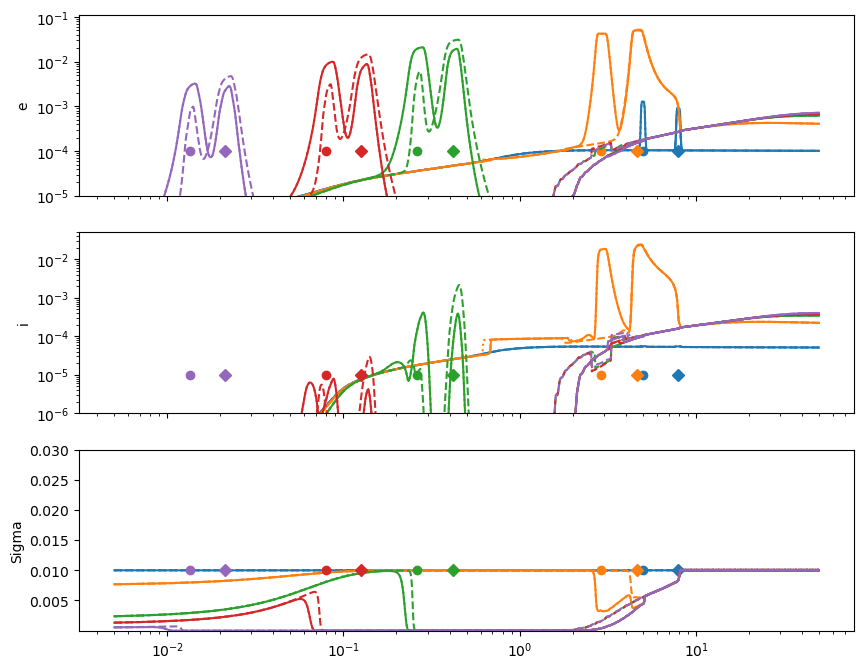

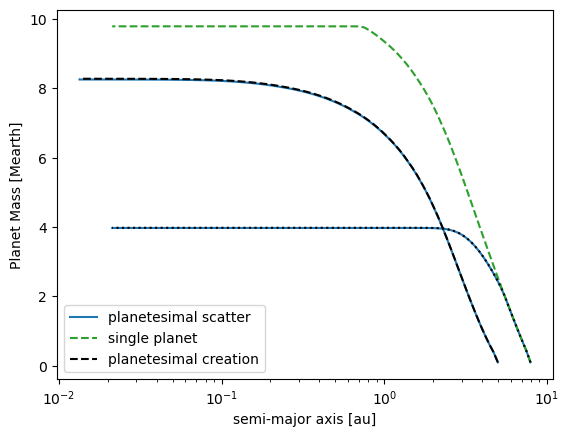

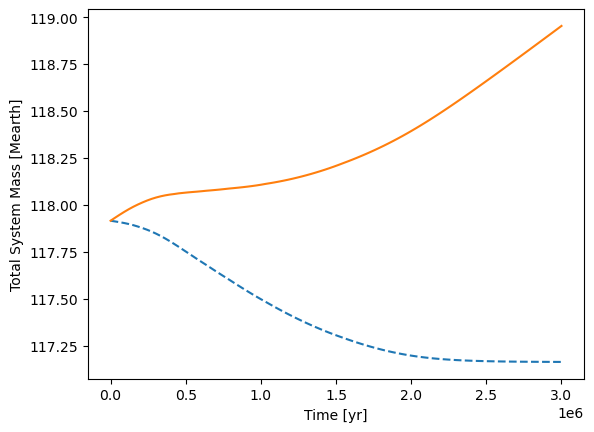

In [75]:
from collections import defaultdict

def run_sys(planets, times, fdot=0, peb_frac=0):
    disc = Disc(peb_frac=peb_frac)
    pl = Planetesimals(0.005, 50, r=10, e0=1e-4, fSigma=1e-2, fdot=fdot)

    psys = PlanetarySystem(disc,pl, planets)

    res = defaultdict(list)
    t = 0
    for ti in times:
        dt = ti - t 
        if dt > 0:
            psys.evolve(dt)

        res['Sigma_pl'].append(psys.planetesimals.fSigma.copy())
        res['e_pl'].append(psys.planetesimals.e.copy())
        res['i_pl'].append(psys.planetesimals.i.copy())
        res['Mp'].append([p.Mc+p.Menv for p in psys.planets])
        res['ap'].append([p.a for p in psys.planets])
        t = ti


    res['Mp'] = np.array(res['Mp'])
    res['ap'] = np.array(res['ap'])

    res['Md'] = np.sum(np.pi*np.diff(pl.ae**2)[None,]*disc.Sigma(pl.a)*res['Sigma_pl']*AU**2/Mearth, axis=1)

    return psys, res

times = np.concatenate([[0], np.linspace(100, 3e6, 100)])*yr
Mp = 0.1
a0 = 5

planets = [
    Planet(Mp/1.1, 0.1*Mp/1.1, a0, tmig=5e5*yr),
    Planet(Mp/1.1, 0.1*Mp/1.1, a0*2**(2/3), tmig=5e5*yr)
]
psys, res = run_sys(planets, times, fdot=0)

#planets = [
#    Planet(Mp/1.1, 0.1*Mp/1.1, a0, tmig=1e6*yr),
#    Planet(Mp/1.1, 0.1*Mp/1.1, a0*2**(2/3), tmig=1e6*yr)
#]

#_, res = run_sys(planets, times, peb_frac=1e-3)

planets2 = [
        Planet(Mp/1.1, 0.1*Mp/1.1, a0*2**(2/3), tmig=5e5*yr),
        Planet(Mp/1.1*1e-10, 0.1*Mp/1.1*1e-10, a0*1**(2/3), tmig=5e5*yr)

]
_, res2 = run_sys(planets2, times, fdot=0)

planets3 = [
    Planet(Mp/1.1, 0.1*Mp/1.1, a0, tmig=5e5*yr),
    Planet(Mp/1.1, 0.1*Mp/1.1, a0*2**(2/3), tmig=5e5*yr)
]

_, res3 = run_sys(planets3, times, fdot=1.5e-5) #extrem production

#_, res3 = run_sys(planets3, times, fdot=1.175e-15) #high production
#_, res3 = run_sys(planets3, times, fdot=1e-15) #moderate production




f, ax = plt.subplots(3, sharex=True, figsize=(10, 8))

for i in [1, 10, 50, 70, 100]:
    c = ax[0].loglog(psys.planetesimals.a, res['e_pl'][i])[0].get_color()
    ax[1].loglog(psys.planetesimals.a, res['i_pl'][i])
    ax[2].semilogx(psys.planetesimals.a, res['Sigma_pl'][i])

    ax[0].loglog(psys.planetesimals.a, res2['e_pl'][i], c=c, ls='--')
    ax[1].loglog(psys.planetesimals.a, res2['i_pl'][i], c=c, ls='--')
    ax[2].semilogx(psys.planetesimals.a, res2['Sigma_pl'][i], c=c, ls='--')
    
    ax[0].loglog(psys.planetesimals.a, res3['e_pl'][i], c=c, ls=':')
    ax[1].loglog(psys.planetesimals.a, res3['i_pl'][i], c=c, ls=':')
    ax[2].semilogx(psys.planetesimals.a, res3['Sigma_pl'][i], c=c, ls=':')
    
    ax[0].plot( res3['ap'][i,0],1e-4,'o', c=c)
    ax[1].plot(res3['ap'][i,0],1e-5,'o', c=c)
    ax[2].plot(res3['ap'][i,0],1e-2,'o', c=c)

    ax[0].plot( res3['ap'][i,1],1e-4,'D', c=c)
    ax[1].plot(res3['ap'][i,1],1e-5,'D', c=c)
    ax[2].plot(res3['ap'][i,1],1e-2,'D', c=c)

ax[0].set_ylim(ymin=1e-5)
ax[1].set_ylim(ymin=1e-6)
ax[2].set_ylim(1e-6, res['Sigma_pl'][0].max()*3)

ax[0].set_ylabel('e')
ax[1].set_ylabel('i')
ax[2].set_ylabel('Sigma')


plt.figure()
plt.semilogx(res['ap'][:,0], res['Mp'][:,0], c='C0')
plt.semilogx(res['ap'][:,1], res['Mp'][:,1], c='C0', label='planetesimal scatter')
plt.semilogx(res2['ap'][:,0], res2['Mp'][:,0], c='C2', ls='--', label='single planet')
plt.semilogx(res3['ap'][:,0], res3['Mp'][:,0],'k--', label='planetesimal creation')
plt.semilogx(res3['ap'][:,1], res3['Mp'][:,1],'k:')
plt.xlabel('semi-major axis [au]')
plt.ylabel('Planet Mass [Mearth]')

plt.legend()
plt.figure()
plt.plot(times/yr, res['Md'] + res['Mp'].sum(axis=1),'--')

plt.plot(times/yr, res3['Md'] + res3['Mp'].sum(axis=1))
plt.xlabel('Time [yr]')
plt.ylabel('Total System Mass [Mearth]')



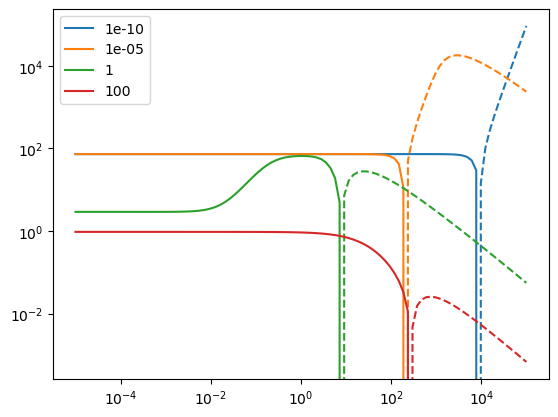

In [76]:
def PQ_VS(e2, i2):
    e,i = np.sqrt(e2), np.sqrt(i2)
    B = i/e
    L2 = i2*(e2 + i2)**2 / 144

    #B = np.maximum(np.minimum(B, 1), 0)

    IP = (B - 0.36251) / (0.061547 + B*(0.16112 + 0.054473*B))
    IQ = (0.71946 - B) / (0.21239  + B*(0.49764 + 0.14369 *B))

    l2 = 72*np.log1p(L2) / (np.pi*i*e)

    P = 7.3*e2                 *np.log1p(10*L2/e2) / L2 + IP*l2 
    Q = (0.4*i2/e + 0.02*i*e2) *np.log1p(10*L2*e ) / L2 + IQ*l2

    return P

for i in [1e-10, 1e-5, 1, 100]:
    e = np.logspace(-5, 5, 100)
    l, =plt.loglog(e, PQ_VS(e**2, i**2), label=str(i))
    plt.loglog(e, -PQ_VS(e**2, i**2), ls='--', c=l.get_color())
plt.legend()